# Decision Tree Regression

**Dataset Name:** California Housing Dataset

**Objective:** Predict median house value based on housing features.

---

## Part A: Conceptual Questions

### 1. What is a Decision Tree Regressor and how does it make predictions?

A Decision Tree Regressor is a supervised machine learning algorithm used to predict continuous numerical values. It divides the dataset into smaller groups based on feature conditions. It makes predictions by following decision rules from the root node to a leaf node. The leaf node predicts the average target value of the training samples present in that leaf.

### 2. What does variance reduction mean in Decision Trees?

Variance reduction means reducing the differences in target values within each group after splitting the data. A Decision Tree selects splits that reduce the variance of the target values, helping to improve prediction accuracy.

### 3. Why do Decision Trees not require feature scaling?

Decision Trees do not require feature scaling because they make decisions using conditions such as whether a feature is less than or greater than a particular value. Scaling does not generally change the relative ordering of feature values, so the splitting process remains the same.

### 4. Why do Decision Trees tend to overfit?

Decision Trees tend to overfit when they grow too deep and learn even small patterns and noise in the training data. They may perform very well on training data but poorly on unseen testing data.

### 5. What role does the max_depth parameter play?

The max_depth parameter controls the maximum depth of a Decision Tree. A smaller depth creates a simpler tree, while a larger depth allows the tree to learn more complex patterns. It helps control overfitting.

### 6. What is bias vs variance in regression?

**Bias:** Error caused by a model making overly simple assumptions. High bias can lead to underfitting.

**Variance:** Error caused by a model being too sensitive to changes in training data. High variance can lead to overfitting.

A good regression model maintains a balance between bias and variance.

## Part B: Data Exploration

In this part, we load the California Housing dataset and explore its structure.

We will display:

- Shape of the dataset
- Column names
- First five rows
- Target column
- Feature columns
- Missing values
- Data types

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Load the Dataset

We use the Pandas library to read the Excel dataset into a DataFrame.

In [5]:
df = pd.read_excel("fetch_california_housing.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
print("Shape of the dataset:", df.shape)

Shape of the dataset: (20640, 9)


### Display Column Names

This helps us identify all the available features and the target column in the dataset.

In [7]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'target']


### Display First Five Rows

The head() function displays the first five records of the dataset. It helps us understand how the data is organized.

In [8]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41,6.984127,1.023810,322,2.555556,37.88,-122.23,4.526
1,8.3014,21,6.238137,0.971880,2401,2.109842,37.86,-122.22,3.585
2,7.2574,52,8.288136,1.073446,496,2.802260,37.85,-122.24,3.521
3,5.6431,52,5.817352,1.073059,558,2.547945,37.85,-122.25,3.413
4,3.8462,52,6.281853,1.081081,565,2.181467,37.85,-122.25,3.422


### Identify Target and Feature Columns

The target column is the variable we want to predict. The remaining columns are the input features used to make predictions.

In [9]:
target_column = 'target'

X = df.drop(columns=[target_column])
y = df[target_column]

print("Target Column:", target_column)

print("\nFeature Columns:")
print(X.columns.tolist())

Target Column: target

Feature Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


### Check Missing Values

We use isnull().sum() to identify the number of missing values in each column.

Missing values are empty or unavailable entries in the dataset.

In [10]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
target        0
dtype: int64


### Check Data Types

The dtypes attribute displays the data type of each column. It helps us understand whether the columns contain integer or floating-point values.

In [11]:
print("Data Types:")
print(df.dtypes)

Data Types:
MedInc        float64
HouseAge        int64
AveRooms      float64
AveBedrms     float64
Population      int64
AveOccup      float64
Latitude      float64
Longitude     float64
target        float64
dtype: object


### Part B: Observation

The dataset contains 20,640 rows and 9 columns. It has 8 feature columns and 1 target column named target.

There are no missing values in the dataset. The columns contain integer and floating-point data types.

## Part C: Data Preprocessing

In this part, we handle missing values if any, separate the independent and dependent variables, and split the dataset into training and testing sets.

### 1. Handle Missing Values

We check for missing values and handle them using the median of each numerical column if any missing values are present.

In [12]:
if df.isnull().sum().sum() > 0:
    df = df.fillna(df.median(numeric_only=True))

print("Missing Values After Handling:")
print(df.isnull().sum())

Missing Values After Handling:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
target        0
dtype: int64


### 2. Separate Features (X) and Target (y)

X contains the independent variables (input features).

y contains the dependent variable (target column) that we want to predict.

In [13]:
X = df.drop(columns=['target'])
y = df['target']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (20640, 8)
Target Shape: (20640,)


### 3. Split the Dataset into Training and Testing Sets

We split the dataset into 80% training data and 20% testing data.

We use random_state=42 to ensure that the same data split can be reproduced whenever we run the code.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (16512, 8)
Testing Features: (4128, 8)
Training Target: (16512,)
Testing Target: (4128,)


## Part D: Model Building

In this part, we create a Decision Tree Regressor using the specified parameters, train the model on training data, and make predictions on testing data.

### 1. Create the Decision Tree Regressor

We use criterion='squared_error' to measure the quality of splits and random_state=42 to ensure reproducibility.

In [15]:
dt_model = DecisionTreeRegressor(
    criterion='squared_error',
    random_state=42
)

### 2. Train the Model

We train the Decision Tree Regressor using the training dataset. The model learns patterns and relationships between the input features and target values.

In [16]:
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

### Make Predictions

After training the Decision Tree Regressor, we use the trained model to predict the median house values for the test dataset.

The model uses the patterns learned during training to predict values for unseen data.

In [17]:
y_pred = dt_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

First 10 Actual Values:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]

First 10 Predicted Values:
[0.414   1.203   5.00001 2.17    2.257   1.664   2.217   1.74    2.772
 5.00001]


## Part E: Model Evaluation

After making predictions, we evaluate the performance of the Decision Tree Regressor using R² Score, Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

These metrics help us understand how closely the predicted values match the actual house values.

#### Calculate Evaluation Metrics

- **R² Score:** Measures how well the model explains the variation in the target values. A score closer to 1 generally indicates a better fit.
- **MAE:** Measures the average absolute difference between actual and predicted values.
- **RMSE:** Measures the square root of the average squared prediction errors. It gives more weight to larger errors.

In [18]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R² Score:", r2)
print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)

R² Score: 0.622823312540521
Mean Absolute Error (MAE): 0.4541711942829458
Root Mean Squared Error (RMSE): 0.7030332265476953


#### Interpretation of Evaluation Metrics

- A higher R² score indicates that the model explains more variation in house values.
- A lower MAE indicates that the predictions are closer to the actual values on average.
- A lower RMSE indicates smaller prediction errors, with larger errors receiving more weight.

We should also compare the training and testing R² scores to understand whether the model is overfitting or underfitting.

In [19]:
y_train_pred = dt_model.predict(X_train)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_pred)

print("Training R² Score:", train_r2)
print("Testing R² Score:", test_r2)

Training R² Score: 1.0
Testing R² Score: 0.622823312540521


### Answers to Model Evaluation Questions

1. **Is the model overfitting or underfitting?**

   The model is overfitting because the training R² score is 1.0000, while the testing R² score is 0.6228.

2. **Compare training and testing R².**

   The training R² score is higher than the testing R² score. This shows that the model performs extremely well on training data but less effectively on unseen test data.

3. **What does R² score indicate?**

   R² indicates how much of the variation in the target variable is explained by the model. A score closer to 1 generally indicates a better fit.

## Part F: Effect of Maximum Depth on Model Performance

The maximum depth controls how many levels a Decision Tree can grow.

A shallow tree may not learn enough patterns from the data, while a very deep tree may learn the training data too closely and overfit.

We will compare models with max_depth values of 3, 7, and None.

### Train Decision Tree Models with Different Depths

We create three Decision Tree Regressor models with different maximum depth values and train them using the training dataset.

In [20]:
depth_values = [3, 7, None]

depth_models = {}

for depth in depth_values:
    model = DecisionTreeRegressor(
        criterion='squared_error',
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)
    depth_models[depth] = model

print("All three Decision Tree models have been trained.")

All three Decision Tree models have been trained.


### Compare Training and Testing R² Scores

We calculate the R² score on both training and testing data for each model.

This comparison helps us understand how well each model performs on known and unseen data.

In [21]:
for depth, model in depth_models.items():
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_score = r2_score(y_train, train_predictions)
    test_score = r2_score(y_test, test_predictions)

    print("Max Depth:", depth)
    print("Training R² Score:", train_score)
    print("Testing R² Score:", test_score)
    print("-" * 40)

Max Depth: 3
Training R² Score: 0.5378979887726012
Testing R² Score: 0.5097629887358219
----------------------------------------
Max Depth: 7
Training R² Score: 0.7166975587892221
Testing R² Score: 0.6515700686011479
----------------------------------------
Max Depth: None
Training R² Score: 1.0
Testing R² Score: 0.622823312540521
----------------------------------------


## Part G: Decision Tree Visualization

Visualizing a Decision Tree helps us understand how the model makes predictions.

Each internal node represents a decision based on a feature, each branch represents an outcome of that decision, and each leaf node represents the predicted value.

### Identify the Best Model

We select the model with the highest testing R² score because it performed better on unseen test data among the three models.

In [22]:
best_depth = None
best_test_score = float('-inf')

for depth, model in depth_models.items():
    predictions = model.predict(X_test)
    score = r2_score(y_test, predictions)

    if score > best_test_score:
        best_test_score = score
        best_depth = depth

best_model = depth_models[best_depth]

print("Best Maximum Depth:", best_depth)
print("Best Testing R² Score:", best_test_score)

Best Maximum Depth: 7
Best Testing R² Score: 0.6515700686011479


### Plot the Best Decision Tree

We use the selected best model and display its decision-making structure with feature names and a descriptive title.

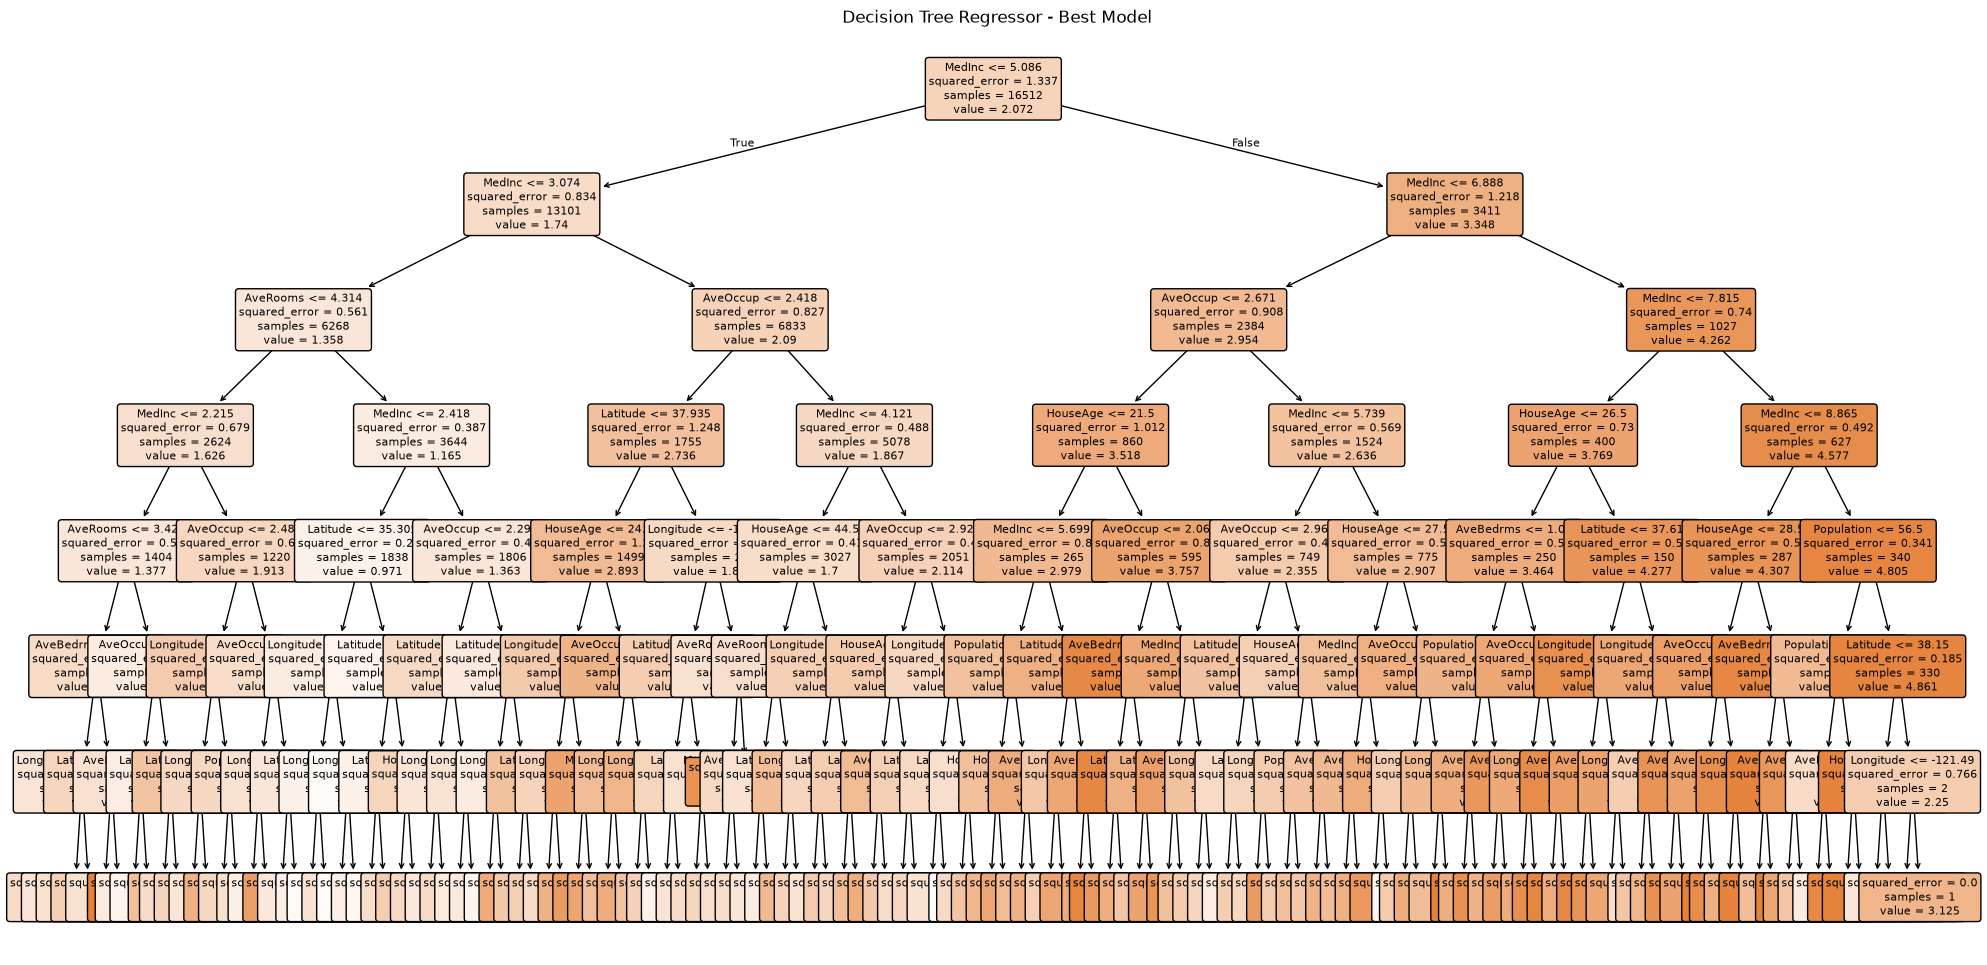

In [23]:
plt.figure(figsize=(24, 12))

plot_tree(
    best_model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Regressor - Best Model")
plt.show()

## Part H: Compare Splitting Criteria and Tune min_samples_leaf

A Decision Tree Regressor supports different criteria for selecting the best split.

In this section, we compare squared_error and absolute_error to understand how the splitting criterion affects model performance.

We also experiment with different min_samples_leaf values to control the minimum number of samples required in each leaf node.

### Compare squared_error and absolute_error

We train two Decision Tree Regressor models using different criteria and compare their training and testing R² scores.

In [24]:
criteria = ['squared_error', 'absolute_error']

criterion_models = {}

for criterion in criteria:
    model = DecisionTreeRegressor(
        criterion=criterion,
        random_state=42
    )

    model.fit(X_train, y_train)
    criterion_models[criterion] = model

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    print("Criterion:", criterion)
    print("Training R² Score:", r2_score(y_train, train_predictions))
    print("Testing R² Score:", r2_score(y_test, test_predictions))
    print("-" * 40)

Criterion: squared_error
Training R² Score: 1.0
Testing R² Score: 0.622823312540521
----------------------------------------
Criterion: absolute_error
Training R² Score: 1.0
Testing R² Score: 0.6012261311544358
----------------------------------------


### Experiment with min_samples_leaf

The min_samples_leaf parameter specifies the minimum number of samples that must be present in a leaf node.

A larger value can make the tree simpler and help reduce overfitting. However, if the value is too large, the model may underfit.

We experiment with different values and compare their training and testing R² scores.

In [25]:
leaf_values = [1, 5, 10, 20]

leaf_results = []

for leaf in leaf_values:
    model = DecisionTreeRegressor(
        criterion='squared_error',
        min_samples_leaf=leaf,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    train_score = r2_score(y_train, train_predictions)
    test_score = r2_score(y_test, test_predictions)

    leaf_results.append({
        'min_samples_leaf': leaf,
        'Training R²': train_score,
        'Testing R²': test_score
    })

leaf_results_df = pd.DataFrame(leaf_results)

print(leaf_results_df)

   min_samples_leaf  Training R²  Testing R²
0                 1     1.000000    0.622823
1                 5     0.910828    0.695330
2                10     0.855444    0.722790
3                20     0.808886    0.727308


### Identify the Best min_samples_leaf Value

We select the min_samples_leaf value that gives the highest testing R² score among the tested values.

A better generalization performance means the model performs well on unseen data, rather than only memorizing the training data.

In [26]:
best_leaf_row = leaf_results_df.loc[
    leaf_results_df['Testing R²'].idxmax()
]

print("Best min_samples_leaf:", best_leaf_row['min_samples_leaf'])
print("Best Testing R² Score:", best_leaf_row['Testing R²'])

Best min_samples_leaf: 20.0
Best Testing R² Score: 0.7273081251592183


### Observations

The comparison of squared_error and absolute_error shows how different splitting criteria affect Decision Tree performance.

The min_samples_leaf experiment shows how controlling the minimum number of samples in a leaf node affects overfitting and generalization.

The model with the highest testing R² score among the tested values demonstrates the best test performance in this experiment.

## Part I: Reflection Questions

### 1. Is a Decision Tree suitable for predicting house prices? Why?

Yes, a Decision Tree Regressor is suitable for predicting house prices because it can learn relationships between different features such as median income, house age, number of rooms, population, and location.

It can capture non-linear relationships and does not require feature scaling. However, its performance depends on the data and model parameters.

### 2. What are the limitations of using a single Decision Tree?

A single Decision Tree can easily overfit the training data, especially when it grows too deep.

Small changes in the training data can also produce a different tree. Additionally, a single tree may not perform as accurately as ensemble models on complex datasets.

### 3. Why are ensemble methods like Random Forest preferred over a single Decision Tree?

Ensemble methods such as Random Forest combine predictions from multiple Decision Trees.

This helps reduce the impact of individual tree errors and generally improves stability and generalization.

Random Forest also reduces the risk of overfitting compared with using a single deep Decision Tree.

## Part J: Conclusion

In this assignment, we implemented a Decision Tree Regressor to predict median house values using the California Housing dataset.

We learned that:

- Decision Trees make predictions by dividing data into smaller groups based on feature values.
- Deep trees can overfit the training data.
- The max_depth parameter controls the growth of the tree and helps manage model complexity.
- Comparing training and testing performance helps identify overfitting and underfitting.
- Different splitting criteria and min_samples_leaf values can affect model performance.
- Hyperparameter tuning helps improve the model's ability to generalize to unseen data.

Overall, this assignment helped us understand how Decision Tree Regression works and how model parameters influence prediction performance.